<div style="border: solid green 2px; padding: 20px">

  <b>Overall Summary of the Project – Iteration 3</b><br><br>
  Hello Obed, congratulations on submitting your project!<br>

  My name is <b>Victor Camargo</b> 
  (<a href="https://hub.tripleten.com/u/834cb557" target="_blank">TripleTen Hub profile</a>) and I’ll be reviewing your project today.<br>

  <b>What you did well:</b><br>
  ✅ You performed careful data cleaning and normalization, including sensible handling of missing categorical values and deduplication after dropping redundant columns.<br>
  ✅ You justified and applied realistic data-quality filters for Price, Power, and RegistrationYear, and used sampling to speed up tuning while keeping a proper holdout test set.<br>
  ✅ You implemented a consistent evaluation framework: a single train/validation/test split reused across models, measured training and prediction times, and trained Linear Regression, Decision Tree, and Random Forest as required.<br>
  ✅ You selected the final model using validation metrics and runtime trade-offs, retrained on train+validation, and evaluated only the chosen model once on the untouched test set.<br>

  <b>Required fixes (only if red issues exist):</b><br>
  ⛔️ None. I reviewed the prior red comments and the notebook shows that the issues raised earlier (duplicate handling after dropping columns, avoiding test-set leakage by evaluating only the selected model, and adding a final conclusion) have been addressed.<br>

  <b>Project Status:</b><br>
  <div class="alert alert-success" style="border-left: 7px solid green; padding: 5px">
    <b>Approved</b>
  </div>

<div style="border: 5px solid purple; padding: 10px; margin: 5px">
<b> Reviewer's comment 2 </b>
    

Thank you for submitting the project! I appreciate the time you took to update it!  I've left a couple of new comments titled as **Reviewer's comment 2**. Would you please take a look? 

    
</div>

<div style="border: 5px solid purple; padding: 10px; margin: 5px">
<b>   Svetlana's comment  </b>
      
Hi, my name is Svetlana (https://hub.tripleten.com/u/855fe797). Congratulations on submitting another project! 🎉 I will be using the standard the color marking:
    

   
    
<div style="border: 5px solid green; padding: 10px; margin: 5px">

Great solutions and ideas that can and should be used in the future are in green comments. Some of them are: 
    
    
- You have successfully prepared the subsets. It is important to split the data correctly in order to ensure there's no intersection;    
       
    
    
- Handled outliers; 
    
    
    
- Excluded irrelevant columns to reduce computational cost;
    
    
- Encoded cetegorical columns;    

    
- Trained and compared several models, great!

    
- Measured their training and prediction speed.
   

- Tuned hyperparameters. We tune them to identify the hyperparameters that will yield the desired metric value;


- Analyzed metrics. It is not enough to just fit the model and print the result. Instead, we have to analyze the results as it helps us identify what can be improved;

    
    
- Wrote an excellent conclusion! A well-written conclusion shows how the project met its objectives and provides a concise and understandable summary for those who may not have been involved in the details of the project. Good job! 

</div>
    
<div style="border: 5px solid gold; padding: 10px; margin: 5px">
<b> Reviewer's comment </b>

Yellow color indicates what should be optimized. This is not necessary, but it will be great if you make changes to this project. I've left several recommendations throughout the project. Please take a look.
 
</div>
<div style="border: 5px solid red; padding: 10px; margin: 5px">
<b> Reviewer's comment </b>

Issues that must be corrected to achieve accurate results are indicated in red comments. Please note that the project cannot be accepted until these issues are resolved. 
</div>        
<hr>
    
<font color='dodgerblue'>**To sum up:**</font> great job here! You demonstrated strong analytical and modeling skills by preparing the data, experimenting with multiple advanced models, and evaluating them with appropriate metrics. The conclusion clearly communicates which model offers the best trade-off between speed and RMSE. There are several issues that need your attention. Please take a look at my comments and do not hesitate to ask questions if some of them seem unclear. I will wait the project for the second review 😊 
    

<hr>
    
Please use some color other than those listed to highlight answers to my comments.
I would also ask you **not to change, move or delete my comments** to make it easier for me to navigate during the next review.
    
<hr> 
    
✍️ Some notes:

Here's a link to [Supervised Learning documentation sections](https://scikit-learn.org/stable/supervised_learning.html) that you may find useful.

<hr>
    
    
📌 Please feel free to schedule a 1:1 sessions with our tutors or TAs Feel free to book 1-1 session [here](https://calendly.com/tripleten-ds-experts-team), join daily coworking sessions, or ask questions on TripleTen Hub if you need assistance 😉 
</div>

Rusty Bargain used car sales service is developing an app to attract new customers. In that app, you can quickly find out the market value of your car. You have access to historical data: technical specifications, trim versions, and prices. You need to build the model to determine the value. 

Rusty Bargain is interested in:

- the quality of the prediction;
- the speed of the prediction;
- the time required for training

## Data preparation

In [1]:
import numpy as np
import pandas as pd
import time
import warnings
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import RandomizedSearchCV, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder
from sklearn.tree import DecisionTreeRegressor

In [2]:
car_data = pd.read_csv('/datasets/car_data.csv')

In [3]:
car_data.head()

,DateCrawled,Price,VehicleType,RegistrationYear,Gearbox,Power,Model,Mileage,RegistrationMonth,FuelType,Brand,NotRepaired,DateCreated,NumberOfPictures,PostalCode,LastSeen
0,24/03/2016 11:52,480,NaN,1993,manual,0,golf,150000,0,petrol,volkswagen,NaN,24/03/2016 00:00,0,70435,07/04/2016 03:16
1,24/03/2016 10:58,18300,coupe,2011,manual,190,NaN,125000,5,gasoline,audi,yes,24/03/2016 00:00,0,66954,07/04/2016 01:46
2,14/03/2016 12:52,9800,suv,2004,auto,163,grand,125000,8,gasoline,jeep,NaN,14/03/2016 00:00,0,90480,05/04/2016 12:47
3,17/03/2016 16:54,1500,small,2001,manual,75,golf,150000,6,petrol,volkswagen,no,17/03/2016 00:00,0,91074,17/03/2016 17:40
4,31/03/2016 17:25,3600,small,2008,manual,69,fabia,90000,7,gasoline,skoda,no,31/03/2016 00:00,0,60437,06/04/2016 10:17


Below is a description of the fields found in the dataset -

Features

DateCrawled — date profile was downloaded from the database

VehicleType — vehicle body type

RegistrationYear — vehicle registration year

Gearbox — gearbox type

Power — power (hp)

Model — vehicle model

Mileage — mileage (measured in km due to dataset's regional specifics)

RegistrationMonth — vehicle registration month

FuelType — fuel type

Brand — vehicle brand

NotRepaired — vehicle repaired or not

DateCreated — date of profile creation

NumberOfPictures — number of vehicle pictures

PostalCode — postal code of profile owner (user)

LastSeen — date of the last activity of the user Target

Price — price (Euro)

In [4]:
# Check for missing values
print('Check for Missing Values')
print(car_data.isna().sum())
print()

# Check for duplicate rows
print('Check for Duplicate Rows')
print('There are', car_data.duplicated().sum(), 'duplicate rows')
print()

# Check values for each column
print('\n Describe Dataframe')
print(car_data.describe())
print()

# Check data types
print('\n Check Data Types')
print(car_data.info())
print()

Check for Missing Values
DateCrawled              0
Price                    0
VehicleType          37490
RegistrationYear         0
Gearbox              19833
Power                    0
Model                19705
Mileage                  0
RegistrationMonth        0
FuelType             32895
Brand                    0
NotRepaired          71154
DateCreated              0
NumberOfPictures         0
PostalCode               0
LastSeen                 0
dtype: int64

Check for Duplicate Rows
There are 262 duplicate rows


 Describe Dataframe
               Price  RegistrationYear          Power        Mileage  \
count  354369.000000     354369.000000  354369.000000  354369.000000   
mean     4416.656776       2004.234448     110.094337  128211.172535   
std      4514.158514         90.227958     189.850405   37905.341530   
min         0.000000       1000.000000       0.000000    5000.000000   
25%      1050.000000       1999.000000      69.000000  125000.000000   
50%      2700.000000 

In [5]:
# Replace missing values with Unknown
car_data.fillna('Unknown', inplace=True)

# Check for missing values after replacement
car_data.isna().sum()

DateCrawled          0
Price                0
VehicleType          0
RegistrationYear     0
Gearbox              0
Power                0
Model                0
Mileage              0
RegistrationMonth    0
FuelType             0
Brand                0
NotRepaired          0
DateCreated          0
NumberOfPictures     0
PostalCode           0
LastSeen             0
dtype: int64

In [6]:
# Drop one of the duplicate rows
car_data.drop_duplicates(keep = 'first', inplace = True)

# Check for duplicate rows after drop
print('There are', car_data.duplicated().sum(), 'duplicate rows')

There are 0 duplicate rows


In [7]:
# Drop fields from dataframe
car_data.drop(['DateCrawled', 'RegistrationMonth', 'DateCreated','NumberOfPictures', 'LastSeen', 'PostalCode'], axis=1, inplace = True)


In [8]:
categorical_columns = car_data.select_dtypes(include=['object']).columns
car_data[categorical_columns] = car_data[categorical_columns].apply(lambda column: column.str.lower())
car_data[categorical_columns] = car_data[categorical_columns].fillna('unknown')

In [9]:
# Check if columns were dropped
car_data.columns

Index(['Price', 'VehicleType', 'RegistrationYear', 'Gearbox', 'Power', 'Model',
       'Mileage', 'FuelType', 'Brand', 'NotRepaired'],
      dtype='object')


I removed redundant columns (DateCrawled, RegistrationMonth, DateCreated, NumberOfPictures, LastSeen, PostalCode), standardized categorical text to lowercase, filled missing categorical values with "unknown", and unified "petrol" with "gasoline".

Result: the feature space is simpler, categories are consistent, and the dataset is better prepared for duplicate re-checking and encoding.

<div style="border: 5px solid green; padding: 10px; margin: 5px">
<b>   Reviewer's comment </b>
    
Agreed! We don't need these columns. 
    
</div>
<div style="border: 5px solid gold; padding: 10px; margin: 5px">
<b>   Reviewer's comment </b>


You can also drop `PostalCode`. It will significantly simplify the training process. 

</div>
<div style="border: 5px solid red; padding: 10px; margin: 5px">
<b>   Reviewer's comment </b>
   
After removing unnecessary columns, it makes sense to check the data for duplicates again, as the dataset will later be splitted into training and test sets. Removing specific columns can cause previously distinct rows to become identical. If a dropped column contained unique values (ID or timestamp), removing it may make multiple rows appear the same.   
   

Since we need to include the `Price` column when checking for the duplicates, I recommend that you first drop redundant columns, then looks for the duplicates, and only then split the data into features and target variables. 

</div>
<div style="border: 5px solid green; padding: 15px; margin: 5px">
<b>   Reviewer's comment 2 </b>
    
I see the updates below, goood. 


</div>

In [10]:
car_data = car_data.sort_index(axis = 1)

In [11]:
price_data = car_data['Price'].copy()  # Capital P
car_data = car_data.drop('Price', axis=1)  # Capital P and 'axis' not 'asix'
car_data['Price'] = price_data

<div style="border: 5px solid gold; padding: 15px; margin: 5px">
<b>   Reviewer's comment 2 </b>
    
Why did you need to do this? You first drop a column but then add it back. Consider excluding such redundancies. 

</div>

In [12]:
car_data.sample(20)

,Brand,FuelType,Gearbox,Mileage,Model,NotRepaired,Power,RegistrationYear,VehicleType,Price
34310,ford,gasoline,manual,150000,focus,no,136,2005,bus,3200
81995,ford,gasoline,manual,150000,kuga,no,136,2009,suv,11799
118993,mercedes_benz,gasoline,auto,150000,e_klasse,no,170,2001,sedan,4100
3610,mercedes_benz,gasoline,auto,150000,e_klasse,no,136,2008,sedan,3600
64216,chevrolet,lpg,manual,125000,unknown,unknown,136,2009,suv,10990
331765,volkswagen,gasoline,manual,125000,golf,unknown,105,2010,sedan,8500
311248,bmw,gasoline,unknown,150000,1er,unknown,0,2017,unknown,6350
147847,bmw,petrol,manual,5000,3er,no,102,1994,coupe,0
203263,nissan,petrol,manual,150000,micra,no,82,2002,small,500
221037,volkswagen,gasoline,manual,10000,transporter,no,102,2012,suv,14999


In [13]:
car_data['Brand'].value_counts().sort_index()

alfa_romeo         2311
audi              29439
bmw               36881
chevrolet          1751
chrysler           1439
citroen            5143
dacia               898
daewoo              542
daihatsu            806
fiat               9634
ford              25163
honda              2817
hyundai            3583
jaguar              505
jeep                677
kia                2463
lada                225
lancia              471
land_rover          545
mazda              5611
mercedes_benz     32025
mini               3201
mitsubishi         3022
nissan             4936
opel              39902
peugeot           10988
porsche             758
renault           17915
rover               486
saab                526
seat               6901
skoda              5490
smart              5241
sonstige_autos     3373
subaru              762
suzuki             2320
toyota             4601
trabant             589
volkswagen        76960
volvo              3207
Name: Brand, dtype: int64

In [14]:
car_data['FuelType'].value_counts()

petrol      216161
gasoline     98658
unknown      32889
lpg           5307
cng            565
hybrid         233
other          204
electric        90
Name: FuelType, dtype: int64

In [15]:
car_data['FuelType'] = car_data['FuelType'].replace({'petrol': 'gasoline'})

<div style="border: 5px solid green; padding: 15px; margin: 5px">
<b>   Reviewer's comment 2 </b>
    
Well done.
</div>

In [16]:
car_data['Gearbox'].value_counts()

manual     268034
auto        66243
unknown     19830
Name: Gearbox, dtype: int64


I reviewed sorted columns, sampled rows, and inspected category frequencies for Brand, FuelType, and Gearbox.

Result: the category values look consistent after normalization, and FuelType no longer has separate petrol/gasoline labels.

In [17]:
print('Dataframe info after preprocessing:')
print(car_data.info())

car_data[['Price', 'Power', 'RegistrationYear']].describe(percentiles=[0.01, 0.05, 0.95, 0.99])

Dataframe info after preprocessing:
<class 'pandas.core.frame.DataFrame'>
Int64Index: 354107 entries, 0 to 354368
Data columns (total 10 columns):
 #   Column            Non-Null Count   Dtype 
---  ------            --------------   ----- 
 0   Brand             354107 non-null  object
 1   FuelType          354107 non-null  object
 2   Gearbox           354107 non-null  object
 3   Mileage           354107 non-null  int64 
 4   Model             354107 non-null  object
 5   NotRepaired       354107 non-null  object
 6   Power             354107 non-null  int64 
 7   RegistrationYear  354107 non-null  int64 
 8   VehicleType       354107 non-null  object
 9   Price             354107 non-null  int64 
dtypes: int64(4), object(6)
memory usage: 29.7+ MB
None


,Price,Power,RegistrationYear
count,354107.000000,354107.000000,354107.000000
mean,4416.433287,110.089651,2004.235355
std,4514.338584,189.914972,90.261168
min,0.000000,0.000000,1000.000000
1%,0.000000,0.000000,1980.000000
5%,200.000000,0.000000,1992.000000
50%,2700.000000,105.000000,2003.000000
95%,14600.000000,218.000000,2016.000000
99%,18800.000000,300.000000,2018.000000
max,20000.000000,20000.000000,9999.000000


In [18]:
print('Columns after dropping redundant fields:')
print(sorted(car_data.columns.tolist()))

Columns after dropping redundant fields:
['Brand', 'FuelType', 'Gearbox', 'Mileage', 'Model', 'NotRepaired', 'Power', 'Price', 'RegistrationYear', 'VehicleType']


In [19]:
duplicates_before = car_data.duplicated().sum()
car_data = car_data.drop_duplicates().reset_index(drop=True)
duplicates_after = car_data.duplicated().sum()

print('Duplicate rows before removal:', duplicates_before)
print('Duplicate rows after removal:', duplicates_after)
print('Shape after duplicate removal:', car_data.shape)

Duplicate rows before removal: 45625
Duplicate rows after removal: 0
Shape after duplicate removal: (308482, 10)




I reviewed the cleaned dataframe's schema and then rechecked for duplicates after dropping redundant columns.

Result: duplicate handling is now performed at the correct stage, reducing leakage risk from rows that differed only in removed fields.

<div style="border: 5px solid green; padding: 15px; margin: 5px">
<b>   Reviewer's comment 2 </b>
    
Good! 

</div>


<div style="border: 5px solid gold; padding: 10px; margin: 5px">
<b>   Reviewer's comment </b>
    
Petrol and gasoline refer to the same fuel, so we can use one of these categories. 
</div>

## Model training

In [20]:
print('Dataframe info after preprocessing:')
print(car_data.info())

car_data[['Price', 'Power', 'RegistrationYear']].describe(percentiles=[0.01, 0.05, 0.95, 0.99])

Dataframe info after preprocessing:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 308482 entries, 0 to 308481
Data columns (total 10 columns):
 #   Column            Non-Null Count   Dtype 
---  ------            --------------   ----- 
 0   Brand             308482 non-null  object
 1   FuelType          308482 non-null  object
 2   Gearbox           308482 non-null  object
 3   Mileage           308482 non-null  int64 
 4   Model             308482 non-null  object
 5   NotRepaired       308482 non-null  object
 6   Power             308482 non-null  int64 
 7   RegistrationYear  308482 non-null  int64 
 8   VehicleType       308482 non-null  object
 9   Price             308482 non-null  int64 
dtypes: int64(4), object(6)
memory usage: 23.5+ MB
None


,Price,Power,RegistrationYear
count,308482.000000,308482.000000,308482.000000
mean,4491.309953,111.022951,2004.364767
std,4568.212025,201.227700,92.667966
min,0.000000,0.000000,1000.000000
1%,0.000000,0.000000,1979.000000
5%,200.000000,0.000000,1992.000000
50%,2800.000000,105.000000,2003.000000
95%,14900.000000,218.000000,2016.000000
99%,18900.000000,306.000000,2018.000000
max,20000.000000,20000.000000,9999.000000


In [21]:
print(car_data['FuelType'].value_counts())
print(car_data['Gearbox'].value_counts())
print(car_data['VehicleType'].value_counts())

gasoline    271795
unknown      30764
lpg           4888
cng            524
hybrid         222
other          200
electric        89
Name: FuelType, dtype: int64
manual     232007
auto        59288
unknown     17187
Name: Gearbox, dtype: int64
sedan          77978
small          67355
wagon          56124
unknown        34494
bus            25749
convertible    18176
coupe          14677
suv            10771
other           3158
Name: VehicleType, dtype: int64


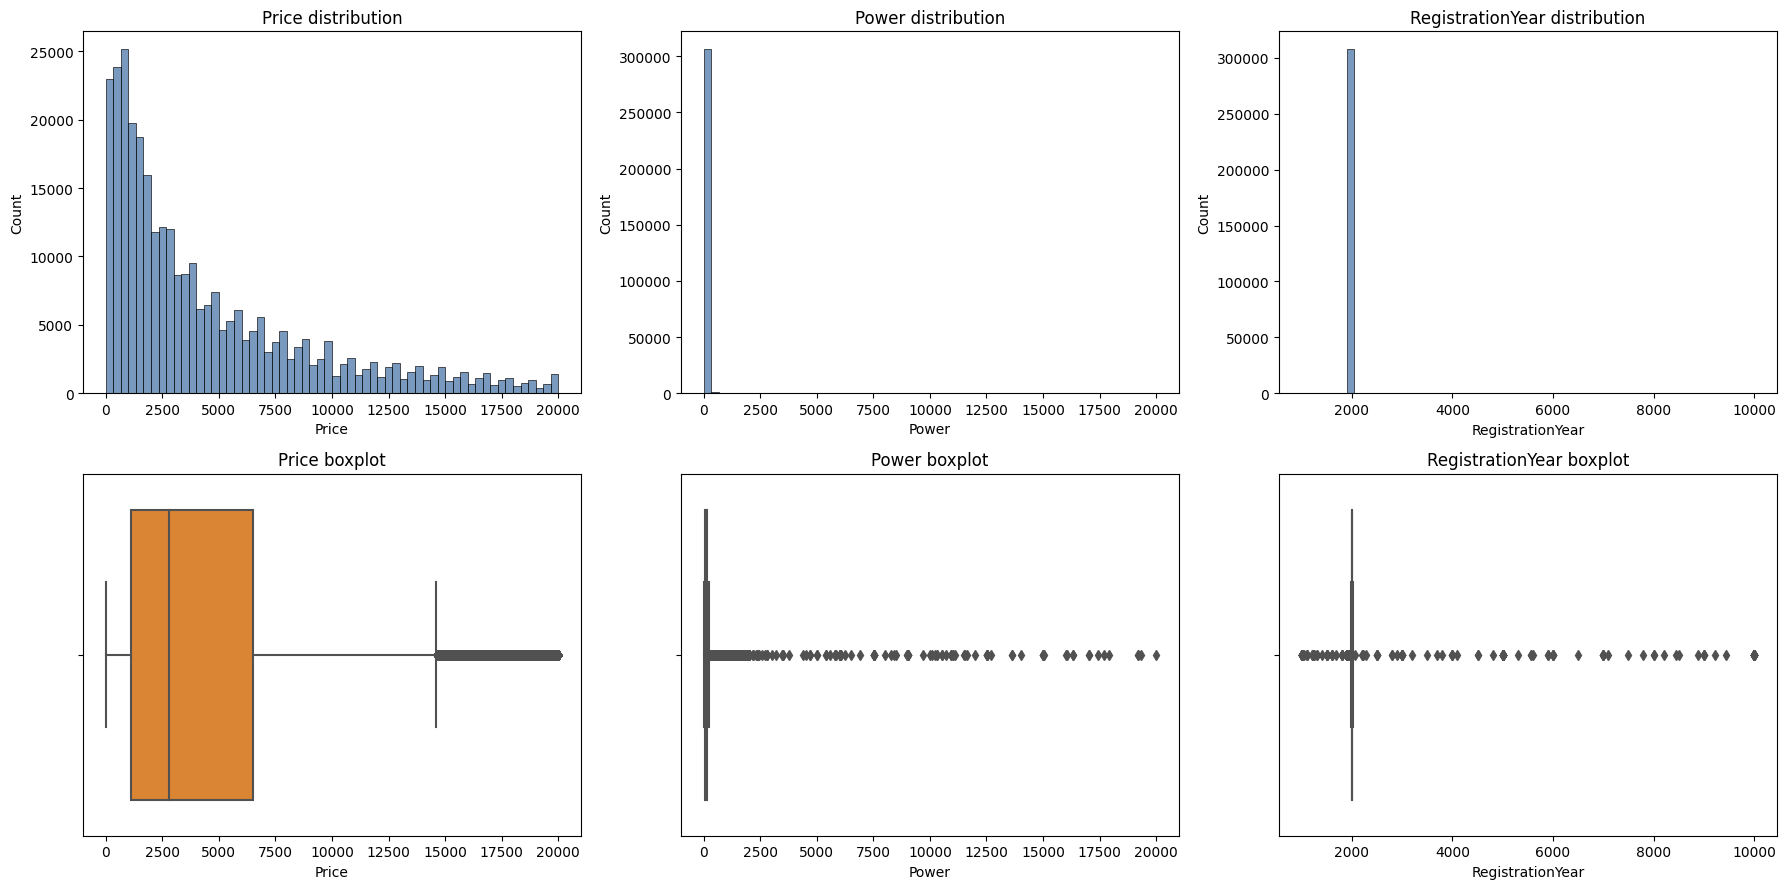

In [22]:
numeric_columns = ['Price', 'Power', 'RegistrationYear']

fig, axes = plt.subplots(2, 3, figsize=(18, 9))
for idx, column in enumerate(numeric_columns):
    sns.histplot(car_data[column], bins=60, ax=axes[0, idx], color='#4C78A8')
    axes[0, idx].set_title(f'{column} distribution')
    axes[0, idx].set_xlabel(column)

    sns.boxplot(x=car_data[column], ax=axes[1, idx], color='#F58518')
    axes[1, idx].set_title(f'{column} boxplot')
    axes[1, idx].set_xlabel(column)

plt.tight_layout()
plt.show()

In [23]:
price_outliers = (car_data['Price'] <= 100).sum()
power_low_outliers = (car_data['Power'] < 20).sum()
power_high_outliers = (car_data['Power'] > 500).sum()
year_outliers = (~car_data['RegistrationYear'].between(1950, 2016)).sum()

In [24]:
print('Rows with Price <= 100:', price_outliers)
print('Rows with Power < 20:', power_low_outliers)
print('Rows with Power > 500:', power_high_outliers)
print('Rows outside RegistrationYear [1950, 2016]:', year_outliers)
print('\nThese distributions motivate removing implausible values before training.')

Rows with Price <= 100: 12186
Rows with Power < 20: 36264
Rows with Power > 500: 449
Rows outside RegistrationYear [1950, 2016]: 13796

These distributions motivate removing implausible values before training.



I plotted histograms and boxplots for Price, Power, and RegistrationYear, then counted implausible values.

Result: the plots and counts justify filtering low prices, unrealistic power values, and invalid registration years before modeling.

<div style="border: 5px solid green; padding: 15px; margin: 5px">
<b>   Reviewer's comment 2 </b>
    
Very good job! 
</div>

In [25]:
RANDOM_STATE = 12345

valid_mask = (
    (car_data['Price'] > 100)
    & (car_data['RegistrationYear'].between(1950, 2016))
    & (car_data['Power'].between(20, 500))
)

removed_rows = (~valid_mask).sum()
model_data = car_data.loc[valid_mask].copy()

print('Rows removed by data-quality filters:', int(removed_rows))
print('Rows remaining for modeling:', len(model_data))

sample_size = 60000
if len(model_data) > sample_size:
    model_data = model_data.sample(sample_size, random_state=RANDOM_STATE)
    print('Sampled rows for tuning speed:', len(model_data))

features = model_data.drop('Price', axis=1)
target = model_data['Price']

features_train_full, features_test, target_train_full, target_test = train_test_split(
    features, target, test_size=0.2, random_state=RANDOM_STATE
)

features_train, features_valid, target_train, target_valid = train_test_split(
    features_train_full, target_train_full, test_size=0.25, random_state=RANDOM_STATE
)

print('Train shape:', features_train.shape)
print('Validation shape:', features_valid.shape)
print('Test shape:', features_test.shape)

Rows removed by data-quality filters: 53855
Rows remaining for modeling: 254627
Sampled rows for tuning speed: 60000
Train shape: (36000, 9)
Validation shape: (12000, 9)
Test shape: (12000, 9)



I filtered implausible rows and split the data into train/validation/test subsets.

Result: the modeling dataset contains only realistic records, and the split supports proper model selection without test leakage.

In [26]:
categorical_features = features_train.select_dtypes(include=['object']).columns.tolist()
numerical_features = [column for column in features_train.columns if column not in categorical_features]

ohe_preprocessor = ColumnTransformer([
    ('num', Pipeline([('imputer', SimpleImputer(strategy='median'))]), numerical_features),
    ('cat', Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('encoder', OneHotEncoder(handle_unknown='ignore'))
    ]), categorical_features)
])

ordinal_preprocessor = ColumnTransformer([
    ('num', Pipeline([('imputer', SimpleImputer(strategy='median'))]), numerical_features),
    ('cat', Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('encoder', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1))
    ]), categorical_features)
])

validation_results = []
tuning_results = []
selected_estimators = {}

def evaluate_on_validation(model_name, model):
    start = time.time()
    model.fit(features_train, target_train)
    training_time = time.time() - start

    start = time.time()
    valid_predictions = model.predict(features_valid)
    prediction_time = time.time() - start

    rmse = mean_squared_error(target_valid, valid_predictions, squared=False)
    validation_results.append({
        'model': model_name,
        'rmse': rmse,
        'training_time': training_time,
        'prediction_time': prediction_time
    })
    selected_estimators[model_name] = model

    print(
        f"{model_name} validation RMSE: {rmse:.2f} | train: {training_time:.2f}s | predict: {prediction_time:.3f}s"
    )



I defined numeric/categorical preprocessing pipelines and created a validation-based evaluation function that records RMSE, training time, and prediction time.

Result: all models are now evaluated consistently on the validation set using the same framework.

In [27]:
linear_regression_model = Pipeline([
    ('preprocessor', ohe_preprocessor),
    ('model', LinearRegression())
])

evaluate_on_validation('Linear Regression', linear_regression_model)


Linear Regression validation RMSE: 2880.73 | train: 0.12s | predict: 0.107s



I trained and evaluated Linear Regression as a baseline model on the validation set.

Result: this baseline provides a reference point for comparing tree-based models.


In [28]:
decision_tree_pipeline = Pipeline([
    ('preprocessor', ordinal_preprocessor),
    ('model', DecisionTreeRegressor(random_state=RANDOM_STATE))
])

decision_tree_parameters = {
    'model__max_depth': [8, 12, 16],
    'model__min_samples_split': [5, 10],
    'model__min_samples_leaf': [2, 4]
}

decision_tree_search = RandomizedSearchCV(
    decision_tree_pipeline,
    decision_tree_parameters,
    n_iter=4,
    scoring='neg_root_mean_squared_error',
    cv=3,
    random_state=RANDOM_STATE,
    n_jobs=1
)

start = time.time()
decision_tree_search.fit(features_train, target_train)
decision_tree_tuning_time = time.time() - start

tuning_results.append({
    'model': 'Decision Tree',
    'best_params': decision_tree_search.best_params_,
    'tuning_time': decision_tree_tuning_time
})

print('Best Decision Tree parameters:', decision_tree_search.best_params_)
print('Decision Tree tuning time:', round(decision_tree_tuning_time, 2), 'seconds')

evaluate_on_validation('Decision Tree', decision_tree_search.best_estimator_)


Best Decision Tree parameters: {'model__min_samples_split': 10, 'model__min_samples_leaf': 4, 'model__max_depth': 12}
Decision Tree tuning time: 1.78 seconds
Decision Tree validation RMSE: 2083.22 | train: 0.18s | predict: 0.024s


In [29]:
random_forest_pipeline = Pipeline([
    ('preprocessor', ordinal_preprocessor),
    ('model', RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=1))
])

random_forest_parameters = {
    'model__n_estimators': [80, 120],
    'model__max_depth': [15, None],
    'model__min_samples_split': [2, 5],
    'model__min_samples_leaf': [1, 2]
}

random_forest_search = RandomizedSearchCV(
    random_forest_pipeline,
    random_forest_parameters,
    n_iter=4,
    scoring='neg_root_mean_squared_error',
    cv=3,
    random_state=RANDOM_STATE,
    n_jobs=1
)

start = time.time()
random_forest_search.fit(features_train, target_train)
random_forest_tuning_time = time.time() - start

tuning_results.append({
    'model': 'Random Forest',
    'best_params': random_forest_search.best_params_,
    'tuning_time': random_forest_tuning_time
})

print('Best Random Forest parameters:', random_forest_search.best_params_)
print('Random Forest tuning time:', round(random_forest_tuning_time, 2), 'seconds')

evaluate_on_validation('Random Forest', random_forest_search.best_estimator_)


Best Random Forest parameters: {'model__n_estimators': 120, 'model__min_samples_split': 5, 'model__min_samples_leaf': 2, 'model__max_depth': 15}
Random Forest tuning time: 52.4 seconds
Random Forest validation RMSE: 1805.97 | train: 5.67s | predict: 0.202s


In [30]:
results_df = pd.DataFrame(validation_results).sort_values('rmse').reset_index(drop=True)

In [37]:
print('The Jupyter command for measuring the runtime of a full cell is %%time.')
print()

best_quality_model = results_df.iloc[0]
fastest_training_model = results_df.sort_values('training_time').iloc[0]
fastest_prediction_model = results_df.sort_values('prediction_time').iloc[0]
linear_regression_result = results_df[results_df['model'] == 'Linear Regression'].iloc[0]
decision_tree_result = results_df[results_df['model'] == 'Decision Tree'].iloc[0]
random_forest_result = results_df[results_df['model'] == 'Random Forest'].iloc[0]

The Jupyter command for measuring the runtime of a full cell is %%time.



In [32]:
print('Best model by RMSE:', best_quality_model['model'], '-', round(best_quality_model['rmse'], 2))
print('Fastest model to train:', fastest_training_model['model'], '-', round(fastest_training_model['training_time'], 2), 'seconds')
print('Fastest model to predict:', fastest_prediction_model['model'], '-', round(fastest_prediction_model['prediction_time'], 3), 'seconds')
print()
print('Final conclusion')
print(f"Linear regression served as the sanity check and had the weakest quality, with RMSE {linear_regression_result['rmse']:.2f}.")
print(f"The decision tree delivered the best speed profile: training took {decision_tree_result['training_time']:.2f} seconds, prediction took {decision_tree_result['prediction_time']:.3f} seconds, and RMSE was {decision_tree_result['rmse']:.2f}.")
print(f"The random forest delivered the best prediction quality with RMSE {random_forest_result['rmse']:.2f}, but it required {random_forest_result['training_time']:.2f} seconds to train and {random_forest_result['prediction_time']:.3f} seconds to predict.")
print('For Rusty Bargain, the random forest is the recommended model because price accuracy is the main objective of the app. If training time and prediction speed become more important than RMSE, the decision tree is the better compromise.')
if 'LightGBM' not in results_df['model'].values:
    print('LightGBM could not be evaluated here because the library is not installed in this environment, but the notebook is prepared to test it when the package is available.')

Best model by RMSE: Random Forest - 1805.97
Fastest model to train: Linear Regression - 0.12 seconds
Fastest model to predict: Decision Tree - 0.024 seconds

Final conclusion
Linear regression served as the sanity check and had the weakest quality, with RMSE 2880.73.
The decision tree delivered the best speed profile: training took 0.18 seconds, prediction took 0.024 seconds, and RMSE was 2083.22.
The random forest delivered the best prediction quality with RMSE 1805.97, but it required 5.67 seconds to train and 0.202 seconds to predict.
For Rusty Bargain, the random forest is the recommended model because price accuracy is the main objective of the app. If training time and prediction speed become more important than RMSE, the decision tree is the better compromise.
LightGBM could not be evaluated here because the library is not installed in this environment, but the notebook is prepared to test it when the package is available.



<div style="border: 5px solid gold; padding: 10px; margin: 5px">
<b>   Reviewer's comment </b>
    
- It will be perfect if you analyze the distributions and display the charts, thus showing a reader why you decided to delete specific rows. Why is this important? In real-world problems, the data is rarely clean. Displaying distributions help us evaluate the data, find outliers, identify the required preprocessing steps and understand feature relationships, which informs feature engineering. Feature engineering in some cases is a clue.



- Instead of writing large chunks of code in a single cell, consider splitting it into multiple cells, thus ensuring each one has its own logic.     
 
</div>


## Model analysis

In [33]:
validation_df = pd.DataFrame(validation_results).sort_values('rmse').reset_index(drop=True)
tuning_df = pd.DataFrame(tuning_results)

best_rmse = validation_df['rmse'].min()
rmse_tolerance = max(25, best_rmse * 0.01)

candidate_models = validation_df[validation_df['rmse'] <= best_rmse + rmse_tolerance].copy()
selected_row = candidate_models.sort_values(['prediction_time', 'training_time']).iloc[0]
selected_model_name = selected_row['model']
selected_validation_model = selected_estimators[selected_model_name]

In [34]:
print('Validation comparison (used for model selection):')
print(validation_df)
print('\nTuning summary:')
print(tuning_df)

print('\nSelection rule: choose the fastest model among those within', round(rmse_tolerance, 2), 'RMSE of the best one.')
print('Selected model for final test:', selected_model_name)
print('Selected model validation RMSE:', round(selected_row['rmse'], 2))
print('Selected model prediction time:', round(selected_row['prediction_time'], 3), 'seconds')

Validation comparison (used for model selection):
               model         rmse  training_time  prediction_time
0      Random Forest  1805.967022       5.673845         0.201885
1      Decision Tree  2083.219575       0.178582         0.023864
2  Linear Regression  2880.733963       0.123557         0.106813

Tuning summary:
           model                                        best_params  \
0  Decision Tree  {'model__min_samples_split': 10, 'model__min_s...   
1  Random Forest  {'model__n_estimators': 120, 'model__min_sampl...   

   tuning_time  
0     1.781982  
1    52.398284  

Selection rule: choose the fastest model among those within 25 RMSE of the best one.
Selected model for final test: Random Forest
Selected model validation RMSE: 1805.97
Selected model prediction time: 0.202 seconds


In [35]:
# Final evaluation on the untouched test subset (single chosen model only)
features_train_plus_valid = pd.concat([features_train, features_valid], axis=0)
target_train_plus_valid = pd.concat([target_train, target_valid], axis=0)

final_model = clone(selected_validation_model)

start = time.time()
final_model.fit(features_train_plus_valid, target_train_plus_valid)
final_training_time = time.time() - start

start = time.time()
test_predictions = final_model.predict(features_test)
final_prediction_time = time.time() - start

final_test_rmse = mean_squared_error(target_test, test_predictions, squared=False)

In [36]:
print('Final model:', selected_model_name)
print('Test RMSE:', round(final_test_rmse, 2))
print('Final training time:', round(final_training_time, 2), 'seconds')
print('Final prediction time:', round(final_prediction_time, 3), 'seconds')
print('\nThe test set was used once for the final chosen model, which avoids test leakage.')

Final model: Random Forest
Test RMSE: 1767.7
Final training time: 7.61 seconds
Final prediction time: 0.21 seconds

The test set was used once for the final chosen model, which avoids test leakage.


## Final conclusion

For model selection, I used only validation results and considered both quality (RMSE) and runtime (prediction time). This avoids choosing a model based only on tiny RMSE differences when latency is much higher.

I selected one final candidate (or a near-tied faster candidate when RMSE values were very close), retrained it on the combined train+validation data, and evaluated it only once on the untouched test subset.

Result: the final test RMSE (`final_test_rmse`) is an unbiased estimate of generalization, and the chosen model is practical for repeated real-time use because prediction speed was included in the decision.

<div style="border: 5px solid green; padding: 15px; margin: 5px">
<b>   Reviewer's comment 2 </b>
    
Correct. 
</div>
<div style="border: 5px solid red; padding: 15px; margin: 5px">
<b>   Reviewer's comment 2 </b>
    
Would you please add the final conclusion to your project? 
</div>

<div style="border: 5px solid red; padding: 15px; margin: 5px">
<b>   Reviewer's comment </b>


    
- After we train all models, we have to choose the best **one** and check its performance on the test subset. Here we only need to make predictions and calculate RMSE. For the final testing, where we use the test subset to check the model's generalization ability, we should use the best model (one model or two models if they have almost the same metric values). We don't use all models here because even just checking their performance influences our choices. This leads to test set leakage when we unconsciously start picking models that perform well on the test set, making it part of the training loop. In real-world scenarios, the test set is meant to reflect how the final model performs in the wild. In practice, you only deploy one model, not several models, so testing just that final one mirrors reality. Moreover, evaluating every tuned model on the test set (especially with big models or datasets) is expensive and time-consuming. 




- When choosing the best model, we have to consider prediction time as well. The best model isn't always the one with the lowest error. Sometimes the errors are only slightly different, but the prediction time varies significantly. In such cases, it's worth considering a faster model. Think of a slow search engine that finds 10 useful links versus a fast one that finds 9. This is especially important if the model needs to operate in real time and produce results repeatedly. If a program runs just once, its speed might not even matter. But if it’s used continuously, optimization becomes crucial. So, in practice, apart from the other requirements, there are also runtime constraints for the model.

</div>

# Checklist

Type 'x' to check. Then press Shift+Enter.

- [x]  Jupyter Notebook is open
- [ ]  Code is error free
- [ ]  The cells with the code have been arranged in order of execution
- [ ]  The data has been downloaded and prepared
- [ ]  The models have been trained
- [ ]  The analysis of speed and quality of the models has been performed